
Simple Hierarchical Multi-Agent System with Groq
===============================================
Shows how to organize agents in teams with team leaders.

Structure:
- CEO (top level)
  - Research Team Leader
    - Data Researcher
    - Market Researcher
  - Writing Team Leader
    - Technical Writer
    - Summary Writer

In [49]:
import langchain
import langsmith
from langgraph.graph import  StateGraph, START, END
from typing import Dict, Any, Annotated, List, Literal
from langchain.chat_models import init_chat_model
from langchain.messages import  HumanMessage, AIMessage 
from langgraph.graph.message import add_messages, MessagesState
import os

from langchain_core.prompts import ChatPromptTemplate
from langchain_tavily import TavilySearch
from langchain_groq import ChatGroq
from langchain.tools import  tool
from dotenv import load_dotenv
load_dotenv()



True

In [50]:
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [51]:
os.environ["LANGSMITH_API_KEY"]= os.getenv("LANGSMITH_API_KEY")

In [52]:
llm = ChatGroq(model ="openai/gpt-oss-120b")

In [53]:
class State(MessagesState):
    current_task: str
    next_agent : str
    research_data: str
    market_insights  : str
    technical_report:str
    final_report : str
    task_complete : bool = False
    messages: Annotated[list[Any], add_messages]


In [54]:
@tool
def research_work(message: str) -> str:
    """Inputs a message and returns a research report."""
    response  = llm.invoke([HumanMessage(content=message)])
    return response.content
@tool
def summary_writing(message: str) -> str:
    """Inputs a message and returns a summary."""
    response = f"Summarize the following content{message[:500]}"
    return response.content



In [55]:
def search_tools(query: str) -> str:
    """Search the web for latest information on the given query."""
    search_tool = TavilySearch()
    result = search_tool.invoke(query)
    return result.content

tools = [research_work, summary_writing]
llm_w_tools = llm.bind_tools(tools)

In [56]:
class CEOGraph(Dict):
    messages:Annotated[List, add_messages]
    next_agent: str


graph = StateGraph(CEOGraph)

graph.add_node("ceo", llm_w_tools)
graph.add_node("research_team_leader", research_work)
graph.add_node("writing_team_leader", llm_w_tools)
graph.add_node("summary_writer", summary_writing)
graph.add_node("data_researcher", llm_w_tools)
graph.add_node("market_researcher",llm_w_tools)
graph.add_node("technical_writer", summary_writing)


graph.add_edge(START,"ceo")
graph.add_edge("ceo", "research_team_leader")
graph.add_edge("ceo", "writing_team_leader")
graph.add_edge("research_team_leader", "ceo")
graph.add_edge("research_team_leader", "data_researcher")
graph.add_edge("research_team_leader", "market_researcher")
graph.add_edge("writing_team_leader", "summary_writer")
graph.add_edge("writing_team_leader", "technical_writer")
graph.add_edge("summary_writer", END)


workflow = graph.compile()

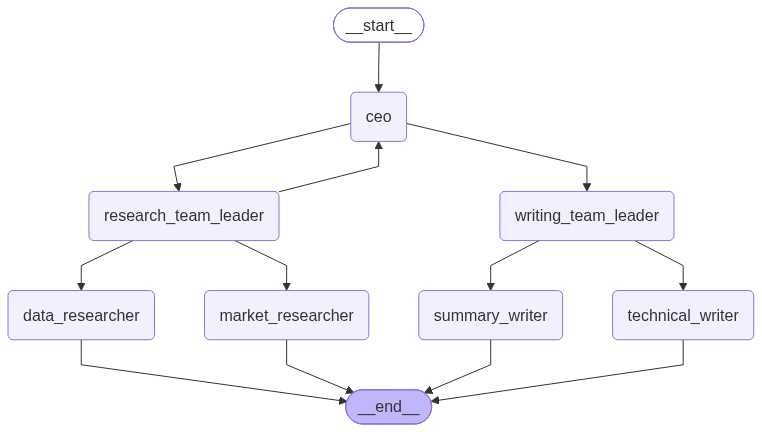

In [57]:
workflow

In [58]:
def ceo_chain():
    """Create a chain of tasks for the CEO agent to manage the workflow."""
    
    ceo_prompt = ChatPromptTemplate.from_messages([('system', """
You are ceo agent, you manage a team of agents.
The query is {task} 
You have to chose betwee the following tasks
1. Resarcher : Gather information and insights 

3. Writer : Create a summarized report about the research 

Based on the current state and converation decide which agent to divert the flow.
Cuurent state:
Researcher:
- Has research data : {has_data}
- Has market insights : {knows_market}
Writer:
- Has technical report : {raw_report}
- Has summarised report : {has_summary}

Respond ONLY with agent name [research_team_leader, writing_team_leader]
If the task is completed  that is all states are true respond wih DONE
""")
, ("human", "{task}")    ])

    return ceo_prompt | llm

In [59]:
def ceo_agent(state: State) ->Dict:
    message = state["messages"]
    task =state.get('current_task') or  (message[0].content if message else "No task")


    has_data= bool(state.get("research_data",""))

    knows_market=bool(state.get("market_insights", ""))

    raw_report = bool(state.get("technical_report", ""))
    has_summary = bool(state.get("final_report", ""))

    chain = ceo_chain()
    decision = chain.invoke({
        "task": task,
        "has_data": has_data,
        "knows_market": knows_market,
        "raw_report": raw_report,
        "has_summary": has_summary
    })
    #parsing
    dec_content = decision.content.strip().lower()
    
    if has_summary:
        task_completed= True
        next_agent = "end"
        print("Task is completed")
    elif "research" in dec_content:
        if not has_data:
            next_agent = "researcher_team_leader"
            print("Activating Research Team")
        elif has_data and not knows_market:
            next_agent = "researcher_team_leader"
            print("Activating Marketing team")
    elif "writing" in dec_content :
        next_agent= "writing_team_leader"
        print("Activating Writing Team")
    else:
        next_agent = "end"
        print("Task maybe completed")
    if "done" in dec_content:
        ceo_msg = f"CEO-AGENT DONE"
    return {
        'message': [AIMessage(content=dec_content)],
        'next_agent': next_agent,
        'current_task' : task
    }

In [60]:
def research_team_leader_chain(state: State):
    """Keyword arguments:
argument -- Current state of workflow
Return: decision made by research team leader agent on which agent to chose next
"""
    

    research_leader_prompt = ChatPromptTemplate.from_messages([('system', """
    You are the leader of research team, there are two agents you have to manage based on 
    1. data_researcher: It collects data from the web based on task
    2. market_researcher: It collects market insights about the topic
    You have to decide which agent to activate based on current state and conversation.

    Respnd ONLY with agent name [data_researcher, market_researcher] or if both are completed then respond 'DONE'
    Current state:
    - Has research data : {has_data}
    - Has market insights : {knows_market}


    """), ('human', "{task}")])

    
    

    

    return research_leader_prompt|llm

In [61]:
def research_leader_decider(state: State) -> Dict:
    """Research leader decides next agent using Groq LLM"""
    
    messages = state.get("messages","")
    task = state.get('current_task',"")
    
    # Check what's been completed
    has_data = bool(state.get("research_data", ""))
    knows_market = bool(state.get("market_insights", ""))
   
    
    # Get LLM decision
    chain = research_team_leader_chain(state)
    decision = chain.invoke({
        
        "has_data": has_data,
        "knows_market": knows_market,
        "task": task,
        })
    
    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)
    
    # Determine next agent
    if "done" in decision_text :
        next_agent = "writing_team_leader"
        supervisor_msg = "✅ Research: All tasks complete! Great work team."
    elif "market_researcher" in decision_text:
        next_agent = "market_researcher"
        supervisor_msg = "📋 Researcher: Let's start with research. Assigning to Marketer..."
   
    elif "data_researcher" in decision_text:
        next_agent = "data_researcher"
        supervisor_msg = "📋 Researcher: Got the task. Researching..."
    else:
        next_agent = "ceo"
        supervisor_msg = "✅ Researcher: Task seems complete."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task
    }

In [62]:
def writing_team_leader_chain(state: State):
    """Keyword arguments:
argument -- Current state of workflow
Return: decision made by writing team leader agent on which agent to chose next
"""

    task =  state.get("current_task","")
    
    

    writing_leader_prompt = ChatPromptTemplate.from_messages([('system', """
    You are the leader of writing team, there are two agents you have to manage for the given task based on research and market data
    Current_task:
    {task}
    Research:
    {research_data} , {market_data}

    

    1. technical_writer: It creates a raw detailed report based on all the research
    2. summary_writer: It creates summary of technical report
    You have to decide which agent to activate based on current state and conversation.
    Prioritize technical writer first and take its output as input to summary_writer
    Respnd ONLY with agent name [technical_writer, summary_writer] or if both are completed then respond 'DONE'
    Current state:
    - If technical report completed : {technical_done}
    - If summary is completed : {summary_done}


    """), ('human', '{task}')])

    
    

    

    return writing_leader_prompt|llm

In [63]:
def writing_leader_decider(state: State) -> Dict:
    """Writing leader decides next agent using Groq LLM"""
    
    messages = state.get('messages','')
    task = state.get('current_task') or (messages[0].content if messages else "No task")

    # Check what's been completed
    technical = bool(state.get("technical_report", ""))
    summary = bool(state.get("final_report", ""))
    research = state.get("research_data","")
    market = state.get("market_insights","")
    
    # Get LLM decision
    chain = writing_team_leader_chain(state)
    decision = chain.invoke({
        "task": task,
        "technical_done": technical,
        "summary_done" : summary,
        "research_data":research,
        "market_data": market
        })
    
    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)
    
    # Determine next agent
    if "done" in decision_text :
        next_agent = "ceo"
        supervisor_msg = "✅ Writer: All tasks complete! Great work team."
    elif "technical_writer" in decision_text or not technical:
        next_agent = "technical_writer"
        supervisor_msg = "📋 Writer: Let's start with writing. Assigning to Technical..."
   
    elif "summary_writer" in decision_text or not summary:
        next_agent = "summary_writer"
        supervisor_msg = "📋 Writer: Got the report. Summarising..."
    else:
        next_agent = "ceo"
        supervisor_msg = "✅ Everything is completed or something broke."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task
    }

In [64]:
def data_researcher(state: State)-> Dict:
    "This node researches about the topic and outputs data"
    task = state['current_task']
    

    dr_prompt = f"""
     You are a data resercher agent. You have to search about the topic from your knowledge and take meaningful insights about {task}.
     Include:
     1. Key facts
     2. Trends and evolution
     3. Changes and solutions
     Be concise but thorough
    """
    dr_response = llm.invoke([HumanMessage(content =dr_prompt)]).content

    agent_message = f"I have completed the data research on {task}. \n \n The findings are {dr_response[:500]}"

    return {
        "messages": [AIMessage(content = agent_message)],
        'current_task' : task,
        'next_agent' : 'market_researcher',
        'research_data' : dr_response
        }

In [65]:
def market_researcher(state:State)->Dict:
    "This node does the mrket research for the given task"
    message = state['messages']
    task = state['current_task']
    
    market_prompt =f""" You are a market researcher agent. You have to extract insights from real market data and analyze that as a real Market Researcher on the given {task}

    Include:
    1. Demand and Supply
    2. Growth of sales
    3. State of competitors 
    Be detailed but structured"""

    mr_response = llm.invoke([HumanMessage(content=market_prompt)]).content

    agent_message = f"Market Research completed for {task}, \n \n The insights are {mr_response[:500]} "

    return {
        "messages": [AIMessage(content=agent_message)],
        "market_insights": mr_response,
        "current_task" : task,
        "next_agent": 'researcher_team_leader'
    }

In [66]:
def technical_writer(state: State)-> Dict:
    "This node takes the research information and creates a detailed report"
    message = state["messages"]
    task = state.get("current_task","")
    research = state.get("research_data","")
    market = state.get("market_insights","")
    technical_prompt = f"""You are a Technical writer agent, your only task is to create a detailed report from the findings by researchers about {task},
    you are provided by following research reports
    RESEARCH_DATA : {research[:1000]}
    MARKET_DATA : {market[:1000]}
    Create a well structured report with:
    1.Topic and Index
    2. Key findings and Insights
    3. Interesting trends
    4. Market study
    5. Recommendation
    6. Conclusion
    Be concise but thorough
    """

    response = llm.invoke([HumanMessage(content=technical_prompt)]).content

    agent_msg = f"I have created technical report\n\n THe insights are {response[:300]}"

    return {"messages": [AIMessage(content=agent_msg)],
            "next_agent": 'writing_team_leader',
            "technical_report":response
            }

In [86]:
import datetime
def summary_writer(state:State)->Dict:
    "This  node creates summary of the technical report"
    report = state.get("technical_report","") 
    task= state.get("current_task", "")

    summary_prompt = f"""You are a report summariser agent. You are given a technical report which you have to summarize under 300 words
    REPORT:
    {report}
    limit = 300
    Include:
    1. Important topics
    2. Key metrics
    3. Short summaries
    Be compacted but cover major topics.
    Keep it related to {task}

    """
    response= llm.invoke([HumanMessage(content=summary_prompt)]).content

    final_report= f""" 
        FINAL REPORT
        {'='*50} 
        Generated at {datetime.date.today}
         {'='*50}
        {response}

           """ 
    return {
        "messages": [AIMessage(content=f"✍️ Writer: Report complete! See below for the full document.")],
        "next_agent": "ceo",
        "final_report" : final_report,
        "task_complete" : True
    }
    

In [68]:
def router(state:State) -> Literal['ceo', 'researcher_team_leader','writing_team_leader','__end__']:
    "Routes to next agent based on state"
    
    node = state.get('next_agent','ceo')
    if node == 'end' or state.get('task_complete', False):
        return END
    if node in ['ceo', 'researcher_team_leader','writing_team_leader', 'summary_writer', 'technical_writer', 'data_researcher', 'market_researcher']:
        return node

    return 'ceo' 




GRAPH

In [69]:
workflow = StateGraph(State)

# Add nodes
workflow.add_node("ceo", ceo_agent)
workflow.add_node("researcher_team_leader", research_leader_decider)
workflow.add_node("data_researcher",data_researcher)
workflow.add_node("market_researcher", market_researcher)
workflow.add_node("writing_team_leader", writing_leader_decider)
workflow.add_node("technical_writer",technical_writer)
workflow.add_node("summary_writer",summary_writer)

# Set entry point
workflow.set_entry_point("ceo")

# Add routing
for node in ['ceo', 'researcher_team_leader','writing_team_leader', 'summary_writer', 'technical_writer', 'data_researcher', 'market_researcher']:
  
    workflow.add_conditional_edges(
        node,
        router,
        {
            'ceo' :'ceo',
            'researcher_team_leader':'researcher_team_leader',
            'writing_team_leader':'writing_team_leader',
            'summary_writer':'summary_writer',
            'technical_writer':'technical_writer',
            'data_researcher':'data_researcher',
            'market_researcher':'market_researcher',
  
            END: END
        }
    )

graph=workflow.compile()

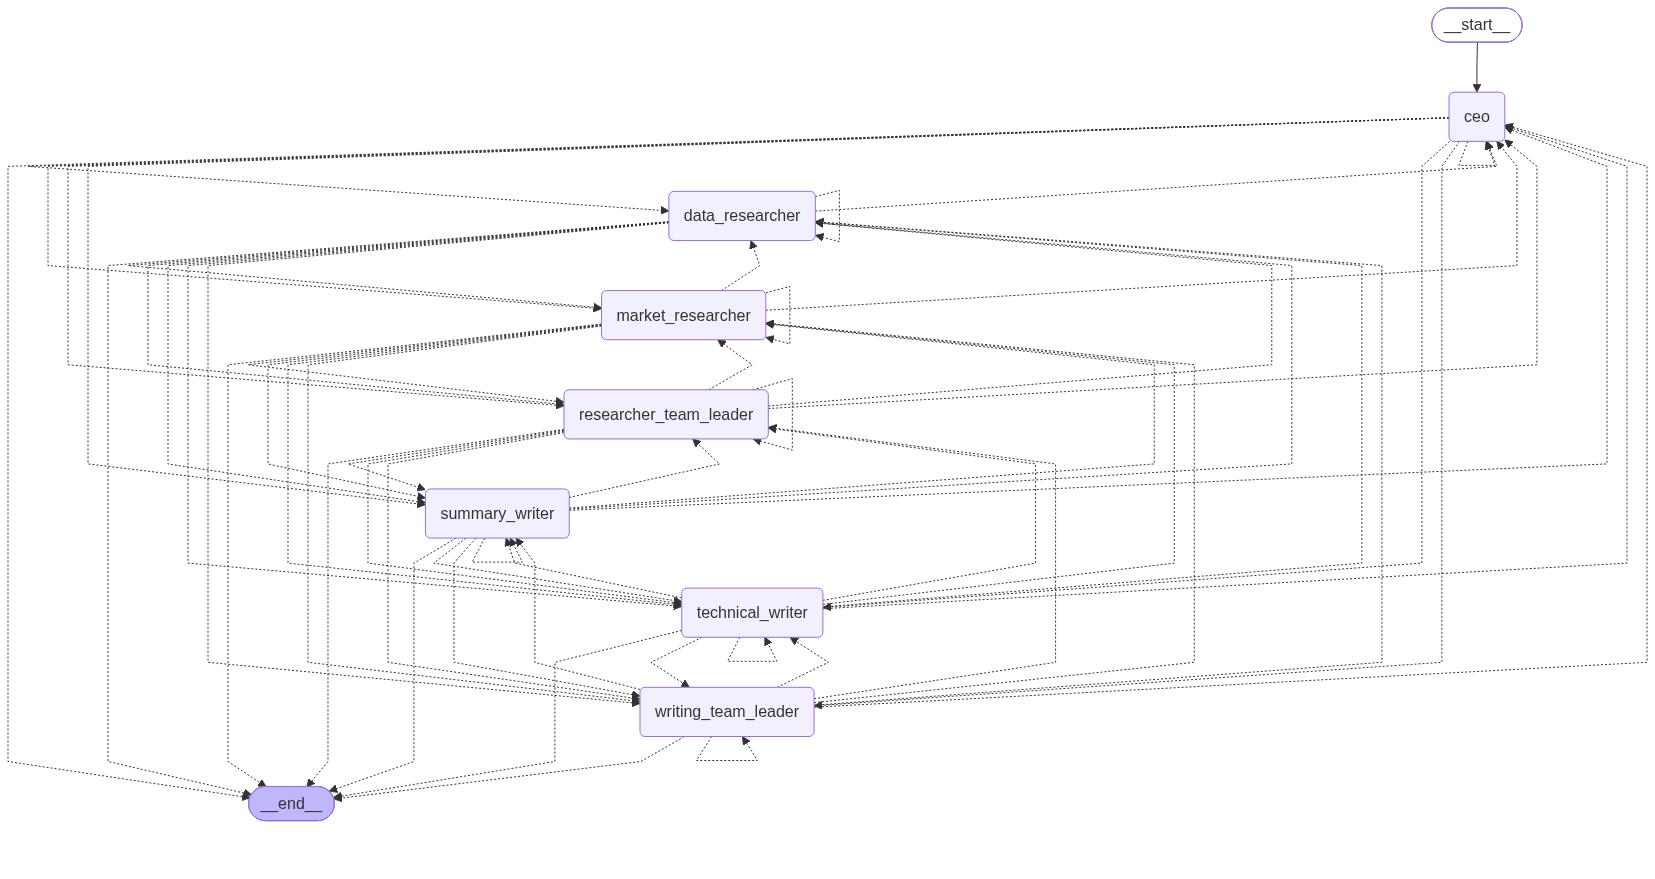

In [70]:
graph

In [84]:
response=graph.invoke({"messages":HumanMessage(content="Research about the Kargil War and create a summary")})

Activating Research Team
data_researcher
done
technical_writer
summary_writer


In [85]:
from pprint import pprint
pprint(response)

{'current_task': 'Research about the Kargil War and create a summary',
 'final_report': ' \n'
                 '        FINAL REPORT\n'
                 '        \n'
                 '    ================================================== \n'
                 '        Generated at <datetime.tzinfo object at '
                 '0x00000220863F5F00>\n'
                 '        \n'
                 '  ==================================================\n'
                 '        **1999 Kargil War – Operational Lessons & '
                 'Defence‑Sector Impact (≈\u202f260\u202fwords)**  \n'
                 '\n'
                 '**1. Operational Overview**  \n'
                 '- **Duration & Theatre:** 3\u202fMay‑26\u202fJuly\u202f1999, '
                 'high‑altitude LoC (13‑18\u202fk\u202fft).  \n'
                 '- **Belligerents:** India vs. Pakistan’s Northern Light '
                 'Infantry & irregulars.  \n'
                 '- **Casualties:** India\u202f≈\u202f527 kill

In [73]:
local_now = datetime.date.today()
print("Local:", local_now)

Local: 2026-10-11
